# 03. Investigação dos dados, consultas SQL e testes de hipóteses

Este notebook analisa a base da etapa 2 e testa as hipóteses da primeira semana. Ele tem três partes:

- **Parte A:** 7 consultas SQL (feitas com DuckDB, direto nos arquivos Parquet).
- **Parte B:** testes das hipóteses H1, H2 e H3.
- **Parte C:** o que os resultados mudam na modelagem.

**Dados usados:** a base diária (`data/processed/`), a série por hora do NE (`data/interim/`) e, para comparar regiões, os arquivos originais do ONS.

**O que é resíduo:** várias consultas comparam o FC real com o **FC esperado para aquele vento**. O resíduo é a diferença entre os dois.
Resíduo negativo quer dizer que as usinas geraram menos do que o vento permitia. Isso costuma indicar corte de geração (*curtailment*): o ONS manda as usinas gerarem menos.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src import clima, config as C

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
ANOS_CORES = {2022: "#86b6ef", 2023: "#5598e7", 2024: "#2a78d6", 2025: "#1c5cab", 2026: "#0d366b"}
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "lines.linewidth": 1.6})
pd.set_option("display.width", 200)

# Vento hora a hora do NE (mesma ponderação da base diária), para a análise por hora
pontos = pd.read_parquet(C.DIR_INTERIM / "pontos_clima.parquet")
mapa = pd.read_parquet(C.DIR_INTERIM / "usinas_pontos_clima.parquet")
usinas_dia = pd.read_parquet(C.DIR_INTERIM / "usinas_dia.parquet")
vento_h, _ = clima.vento_horario(pontos)
vento_ne_h = clima.indice_vento_ne_horario(vento_h, usinas_dia, mapa)

con = duckdb.connect()
con.sql(f"create view base as select * from '{C.BASE_FINAL.as_posix()}'")
con.sql(f"""create view horario as
    select h.din_instante, h.fc, v.vento_100m_ms
    from '{(C.DIR_INTERIM / "fc_eolico_ne_horario.parquet").as_posix()}' h
    join vento_ne_h v using (din_instante)""")

def sql(consulta):
    """Roda uma consulta SQL e devolve um DataFrame."""
    return con.sql(consulta).df()

sql("select count(*) dias, min(data) inicio, max(data) fim from base")

,dias,inicio,fim
0,1765,2022-01-01,2026-10-31


# Parte A. Consultas SQL

## Consulta 1. Sazonalidade: FC e vento por mês

**Pergunta:** em que meses o FC é maior? Isso se repete todo ano?

Primeiro a consulta calcula o FC de cada mês de cada ano (CTE `mensal`). Depois, para cada mês, mostra a média dos anos, o pior ano e o melhor ano.

In [2]:
q1 = sql("""
with mensal as (
    select ano, mes, avg(fc) as fc, avg(vento_100m_ms) as vento
    from base
    group by ano, mes
)
select mes,
       round(avg(fc), 3)    as fc_medio,
       round(min(fc), 3)    as fc_pior_ano,
       round(max(fc), 3)    as fc_melhor_ano,
       round(avg(vento), 2) as vento_medio_ms
from mensal
group by mes
order by mes
""")
q1

,mes,fc_medio,fc_pior_ano,fc_melhor_ano,vento_medio_ms
0,1,0.282,0.225,0.340,5.09
1,2,0.312,0.222,0.400,5.38
2,3,0.297,0.230,0.344,5.08
3,4,0.294,0.263,0.333,5.19
4,5,0.390,0.365,0.432,6.41
5,6,0.427,0.386,0.469,6.89
6,7,0.471,0.405,0.511,7.50
7,8,0.482,0.445,0.557,7.72
8,9,0.486,0.433,0.544,7.89
9,10,0.452,0.385,0.532,7.46


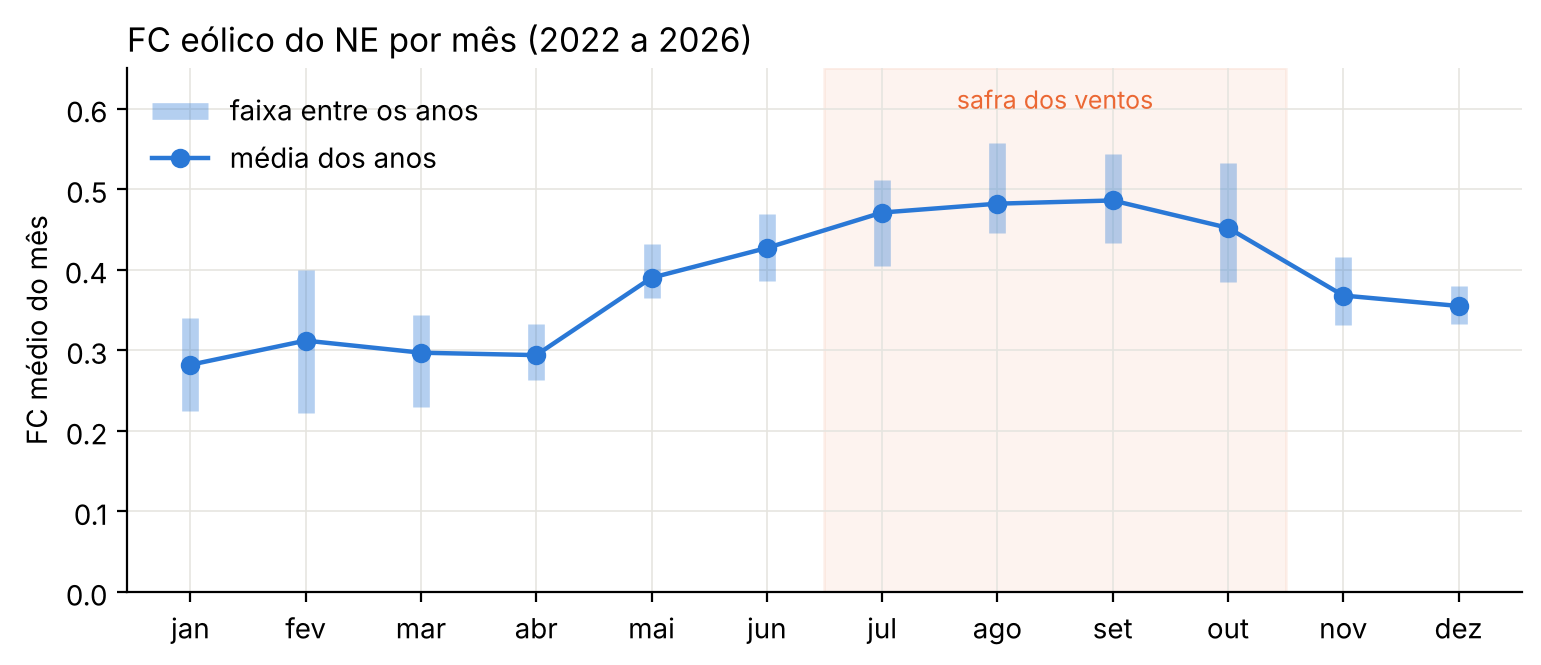

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.vlines(q1["mes"], q1["fc_pior_ano"], q1["fc_melhor_ano"], color=AZUL, alpha=0.35, linewidth=6, label="faixa entre os anos")
ax.plot(q1["mes"], q1["fc_medio"], "o-", color=AZUL, label="média dos anos")
ax.axvspan(6.5, 10.5, color=LARANJA, alpha=0.08)
ax.text(8.5, 0.6, "safra dos ventos", ha="center", color=LARANJA, fontsize=9)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"])
ax.set_ylim(0, 0.65); ax.set_ylabel("FC médio do mês")
ax.set_title("FC eólico do NE por mês (2022 a 2026)", loc="left"); ax.legend(frameon=False, loc="upper left")
plt.show()

**Interpretação:** o FC acompanha o vento. De julho a outubro (safra dos ventos) o FC fica perto de 0,45 a 0,49. De janeiro a abril fica perto de 0,28 a 0,31.

Isso se repete todo ano: o pior agosto ainda é melhor que o melhor janeiro.

**Para a modelagem:** o mês precisa entrar como variável.

## Consulta 2. Tendência: o FC está mudando com o tempo?

**Pergunta:** tirando o efeito das estações, o FC está subindo ou caindo?

A consulta usa duas funções de janela:

- `lag(..., 12)`: compara cada mês com o **mesmo mês do ano anterior**.
- `avg(...) over (rows between 11 preceding and current row)`: **média móvel de 12 meses**, ou seja, a média do mês e dos 11 meses anteriores. Como cada janela tem um mês de cada tipo, as estações se cancelam e sobra a tendência.

In [4]:
q2 = sql("""
with mensal as (
    select date_trunc('month', data) as mes, avg(fc) as fc, avg(vento_100m_ms) as vento
    from base
    group by 1
)
select mes,
       round(fc, 3) as fc,
       round(vento, 2) as vento,
       round(fc - lag(fc, 12) over (order by mes), 3)       as dif_fc_vs_ano_anterior,
       round(vento - lag(vento, 12) over (order by mes), 2) as dif_vento_vs_ano_anterior,
       round(avg(fc) over (order by mes rows between 11 preceding and current row), 3) as fc_media_movel_12m
from mensal
order by mes
""")
q2.tail(12)

,mes,fc,vento,dif_fc_vs_ano_anterior,dif_vento_vs_ano_anterior,fc_media_movel_12m
46,2025-11-01,0.347,6.60,-0.070,-0.04,0.389
47,2025-12-01,0.333,5.97,-0.047,-0.16,0.385
48,2026-01-01,0.328,6.16,0.104,1.60,0.393
49,2026-02-01,0.222,4.53,-0.111,-1.72,0.384
50,2026-03-01,0.233,4.63,-0.111,-1.11,0.375
51,2026-04-01,0.301,5.52,-0.005,0.23,0.374
52,2026-05-01,0.378,6.52,-0.054,-0.50,0.370
53,2026-06-01,0.396,6.77,-0.047,-0.34,0.366
54,2026-07-01,0.405,7.22,-0.047,-0.28,0.362
55,2026-08-01,0.445,7.66,-0.012,-0.15,0.361


In [5]:
comp = q2.dropna(subset=["dif_fc_vs_ano_anterior"])
print("meses comparáveis:", len(comp))
print("meses com MAIS vento e MENOS FC que no ano anterior:",
      ((comp["dif_vento_vs_ano_anterior"] > 0) & (comp["dif_fc_vs_ano_anterior"] < 0)).sum())
print("média móvel de 12 meses: dez/2022 =", q2.loc[q2["mes"] == "2022-12-01", "fc_media_movel_12m"].item(),
      "| out/2026 =", q2["fc_media_movel_12m"].iloc[-1])
sql("""select ano, round(avg(fc), 3) as fc_medio, round(avg(vento_100m_ms), 2) as vento_medio
       from base group by ano order by ano""")

meses comparáveis: 46
meses com MAIS vento e MENOS FC que no ano anterior: 5
média móvel de 12 meses: dez/2022 = 0.405 | out/2026 = 0.35


,ano,fc_medio,vento_medio
0,2022,0.405,6.24
1,2023,0.397,6.42
2,2024,0.382,6.38
3,2025,0.385,6.72
4,2026,0.354,6.34


**Interpretação:** a média móvel de 12 meses caiu de 0,405 (dez/2022) para 0,350 (out/2026), uma queda de cerca de 14%.

O vento não explica essa queda. 2025 foi o ano de vento mais forte (6,72 m/s) e mesmo assim teve FC menor que 2022 (0,385 contra 0,405, com vento de 6,24 m/s).

Ou seja, existe uma perda que não vem do vento. A consulta 3 mostra essa perda com mais clareza.

## Consulta 3. O mesmo vento gera o mesmo FC todo ano?

**Pergunta:** em dias com o mesmo vento, o FC mudou de um ano para outro?

Comparar o FC de 2022 com o de 2026 direto não é justo, porque um ano pode ter ventado mais. Por isso a consulta compara só dias com vento parecido:

1. Cada dia vai para uma **faixa de vento** de 1 m/s (um dia com 8,4 m/s fica na faixa 8).
2. Para cada faixa e cada ano, calcula o FC médio.
3. Combinações com menos de 5 dias ficam vazias (NaN), porque a média seria pouco confiável.

In [6]:
q3 = sql("""
with faixas as (
    select *, floor(vento_100m_ms) as faixa_vento
    from base
),
por_ano as (
    select faixa_vento, ano, avg(fc) as fc, count(*) as dias
    from faixas
    group by faixa_vento, ano
    having count(*) >= 5
)
pivot por_ano on ano using round(first(fc), 3)
group by faixa_vento
order by faixa_vento
""")
q3

,faixa_vento,2022,2023,2024,2025,2026
0,2.0,NaN,NaN,0.070,NaN,NaN
1,3.0,0.152,0.149,0.149,0.135,0.144
2,4.0,0.242,0.229,0.227,0.233,0.211
3,5.0,0.343,0.342,0.320,0.314,0.310
4,6.0,0.433,0.420,0.407,0.382,0.383
5,7.0,0.525,0.493,0.477,0.456,0.431
6,8.0,0.605,0.528,0.529,0.481,0.471
7,9.0,0.674,0.545,0.548,0.490,0.496


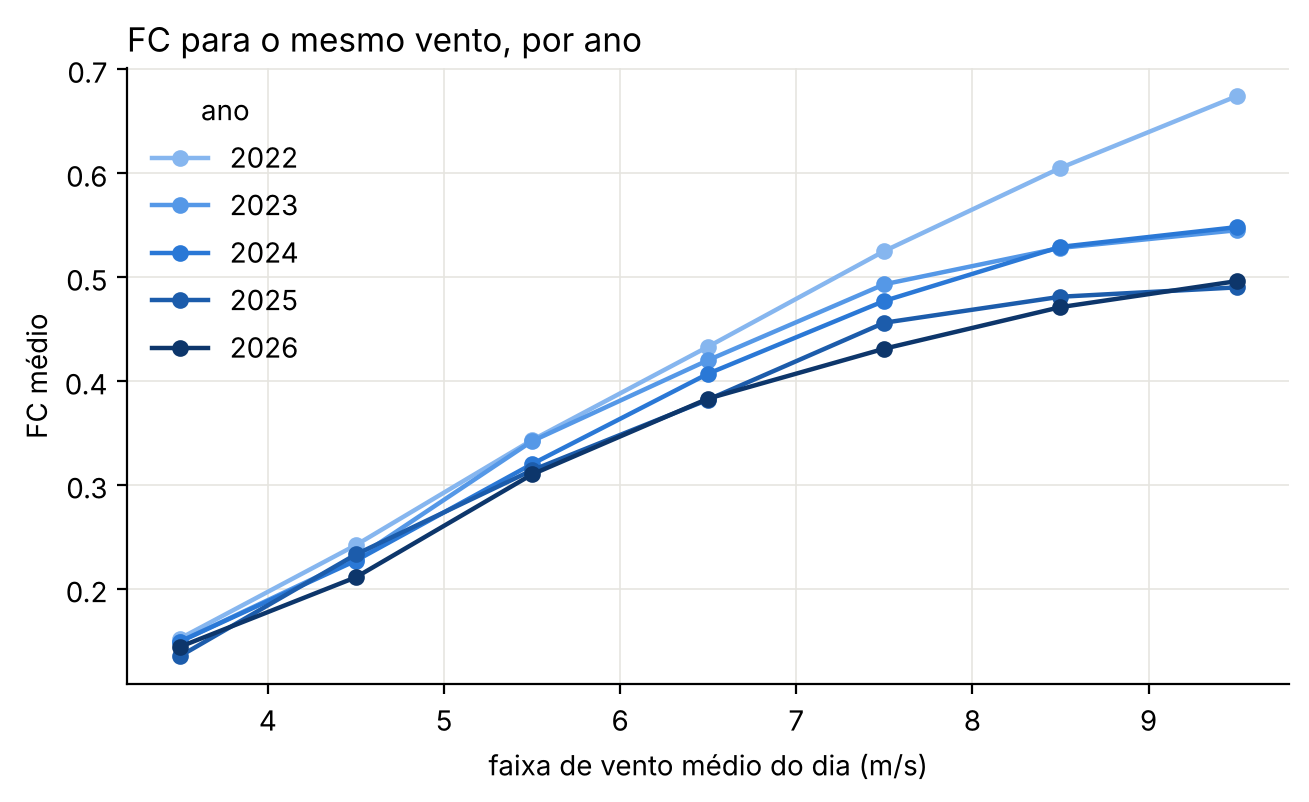

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
q3_graf = q3[q3["faixa_vento"] >= 3]          # a faixa de 2 m/s só tem dados de 2024
for ano, cor in ANOS_CORES.items():
    col = str(ano)
    ax.plot(q3_graf["faixa_vento"] + 0.5, q3_graf[col], "o-", color=cor, label=col, markersize=5)
ax.set_xlabel("faixa de vento médio do dia (m/s)"); ax.set_ylabel("FC médio")
ax.set_title("FC para o mesmo vento, por ano", loc="left"); ax.legend(frameon=False, title="ano")
plt.show()

**Interpretação:** com vento fraco (3 a 4 m/s), o FC é quase igual em todos os anos. Com vento forte, o FC cai a cada ano. Na faixa de 8 m/s ele foi de 0,60 (2022) para 0,47 (2026).

Esse é o sinal do **corte de geração**: com pouco vento não sobra energia e nada é cortado; com muito vento sobra energia e o ONS manda reduzir.
Os cortes nas eólicas do NE cresceram muito a partir de agosto de 2023 e chegaram a 13% da geração eólica em setembro de 2024
([GESEL/UFRJ](https://gesel.ie.ufrj.br/wp-content/uploads/2025/01/Artigo-Claudio-Sales-Richard-Hochstetler-e-Eduardo-Muller-26.12.2024.pdf)).
Outras causas possíveis, menores, são usinas novas em locais com menos vento e o desgaste das turbinas.

**Para a modelagem:** a relação entre vento e FC muda com o tempo. Um modelo treinado só com 2022 erraria para cima em 2026.

## Consulta 4. FC por hora do dia

**Pergunta:** em que horas o FC é maior? As horas com perda mudaram com os anos?

A consulta usa os dados de **2022** (antes do aumento dos cortes) como referência: calcula o FC esperado para cada faixa de vento. Depois mostra o resíduo médio de cada hora em cada ano.

In [8]:
q4 = sql("""
with h as (
    select *, round(vento_100m_ms) as faixa_vento,
           hour(din_instante) as hora, year(din_instante) as ano
    from horario
),
esperado as (
    select faixa_vento, avg(fc) as fc_esperado
    from h
    where ano = 2022
    group by faixa_vento
),
residuos as (
    select h.hora, h.ano, h.fc, h.vento_100m_ms, h.fc - e.fc_esperado as residuo
    from h join esperado e using (faixa_vento)
)
pivot (select hora, ano, avg(residuo) as residuo from residuos group by hora, ano)
on ano using round(first(residuo), 3)
order by hora
""")
perfil = sql("""select hour(din_instante) as hora, round(avg(fc), 3) as fc, round(avg(vento_100m_ms), 2) as vento
                 from horario group by 1 order by 1""")
perfil.merge(q4, on="hora")

,hora,fc,vento,2022,2023,2024,2025,2026
0,0,0.478,6.71,0.042,0.025,0.019,0.031,0.030
1,1,0.475,6.62,0.044,0.027,0.030,0.037,0.033
2,2,0.471,6.54,0.043,0.029,0.038,0.041,0.034
3,3,0.467,6.48,0.041,0.030,0.040,0.041,0.036
4,4,0.462,6.42,0.039,0.030,0.043,0.039,0.039
5,5,0.454,6.36,0.036,0.026,0.040,0.034,0.040
6,6,0.422,6.28,0.024,0.011,0.012,-0.009,0.013
7,7,0.388,6.38,0.022,-0.018,-0.037,-0.080,-0.047
8,8,0.364,6.78,-0.005,-0.056,-0.091,-0.151,-0.137
9,9,0.326,6.77,-0.026,-0.082,-0.118,-0.201,-0.197


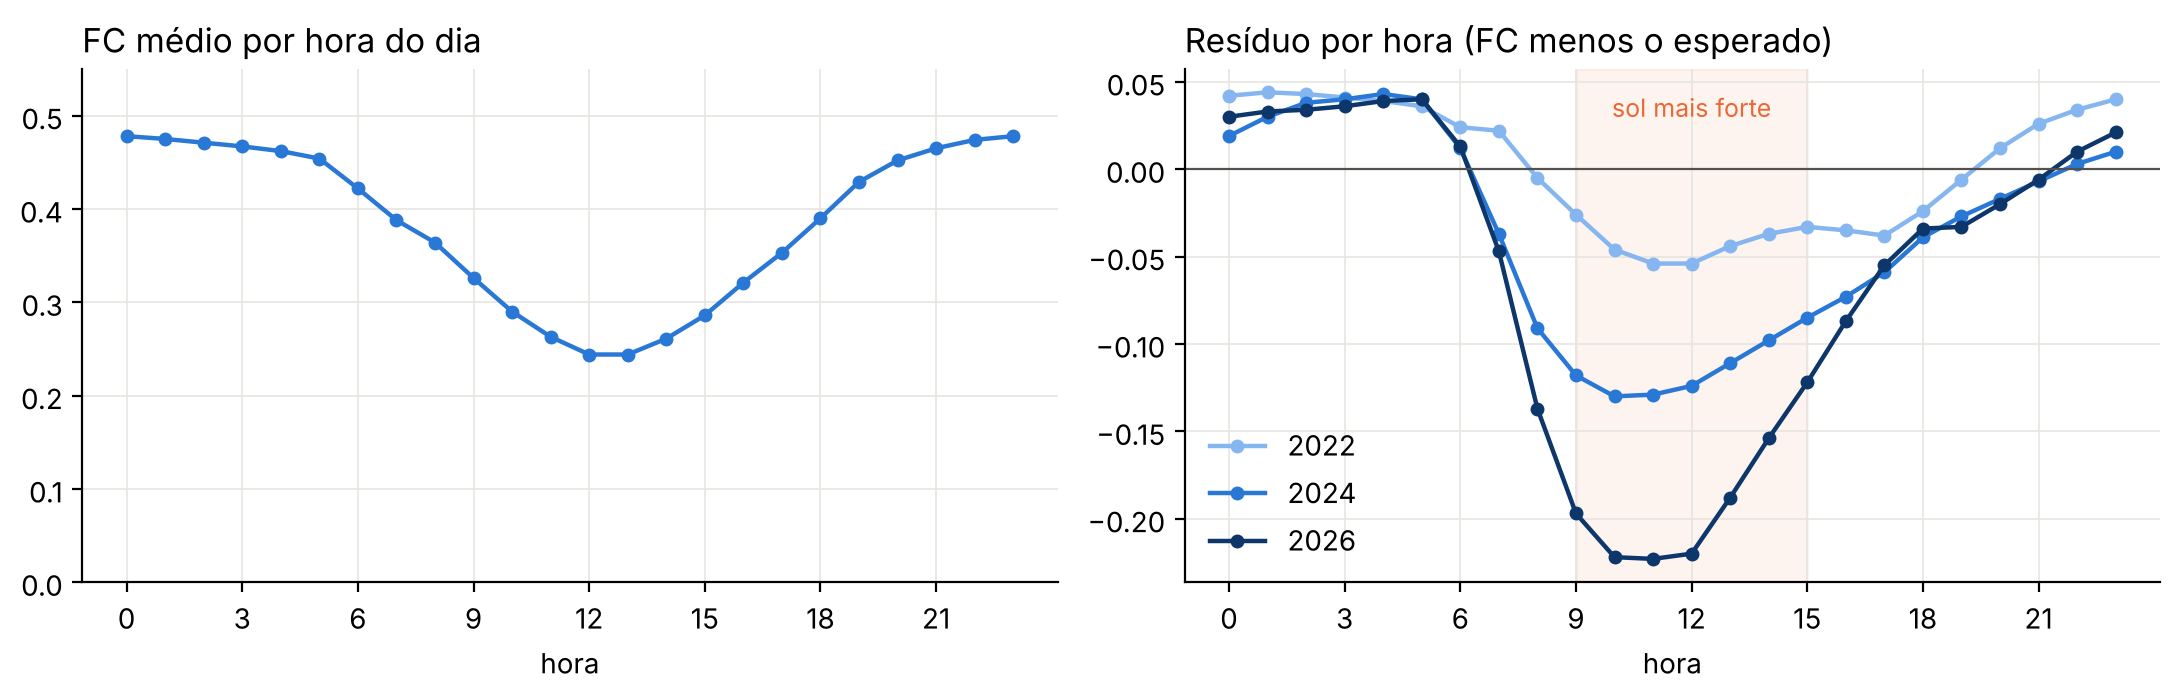

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(perfil["hora"], perfil["fc"], "o-", color=AZUL, markersize=4)
axs[0].set_title("FC médio por hora do dia", loc="left"); axs[0].set_xlabel("hora"); axs[0].set_ylim(0, 0.55)
for ano in [2022, 2024, 2026]:
    axs[1].plot(q4["hora"], q4[str(ano)], "o-", color=ANOS_CORES[ano], label=str(ano), markersize=4)
axs[1].axhline(0, color=CINZA, linewidth=0.8)
axs[1].axvspan(9, 15, color=LARANJA, alpha=0.08); axs[1].text(12, 0.03, "sol mais forte", ha="center", color=LARANJA, fontsize=9)
axs[1].set_title("Resíduo por hora (FC menos o esperado)", loc="left"); axs[1].set_xlabel("hora")
axs[1].legend(frameon=False, loc="lower left")
for ax in axs: ax.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.show()

**Interpretação:**

- O FC é maior de noite (cerca de 0,48) e menor perto do meio-dia (cerca de 0,24). Parte disso é natural: no NE venta mais à noite.
- O gráfico da direita mostra o que mudou. De noite, o resíduo ficou igual em todos os anos. Entre 9h e 15h, piorou muito: de cerca de -0,05 em 2022 para cerca de -0,22 em 2025 e 2026.
- Esse é o horário de sol forte, quando as usinas solares do NE geram mais. Com energia sobrando, o ONS corta parte das eólicas.

**Para a modelagem:** na previsão diária, isso aparece como uma perda que cresce a cada ano.

## Consulta 5. Dia da semana

**Pergunta:** com o mesmo vento, o FC muda conforme o dia da semana?

A consulta calcula o FC esperado para cada faixa de vento de 0,5 m/s e depois o resíduo médio de cada dia da semana. Na base, `dia_semana` vai de 0 (segunda) a 6 (domingo).

In [10]:
q5 = sql("""
with faixas as (
    select *, round(vento_100m_ms * 2) / 2 as faixa_vento
    from base
),
esperado as (
    select faixa_vento, avg(fc) as fc_esperado
    from faixas
    group by faixa_vento
)
select dia_semana,
       count(*)                                as dias,
       round(avg(f.fc), 3)                     as fc_medio,
       round(avg(f.vento_100m_ms), 2)          as vento_medio,
       round(avg(f.fc - e.fc_esperado), 4)     as residuo_medio
from faixas f join esperado e using (faixa_vento)
group by dia_semana
order by dia_semana
""")
q5.insert(1, "dia", ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"])
q5

,dia_semana,dia,dias,fc_medio,vento_medio,residuo_medio
0,0,seg,252,0.392,6.42,0.0055
1,1,ter,252,0.394,6.43,0.0082
2,2,qua,252,0.393,6.45,0.0054
3,3,qui,252,0.388,6.43,0.0020
4,4,sex,252,0.389,6.40,0.0037
5,5,sáb,253,0.382,6.42,-0.0024
6,6,dom,252,0.363,6.42,-0.0226


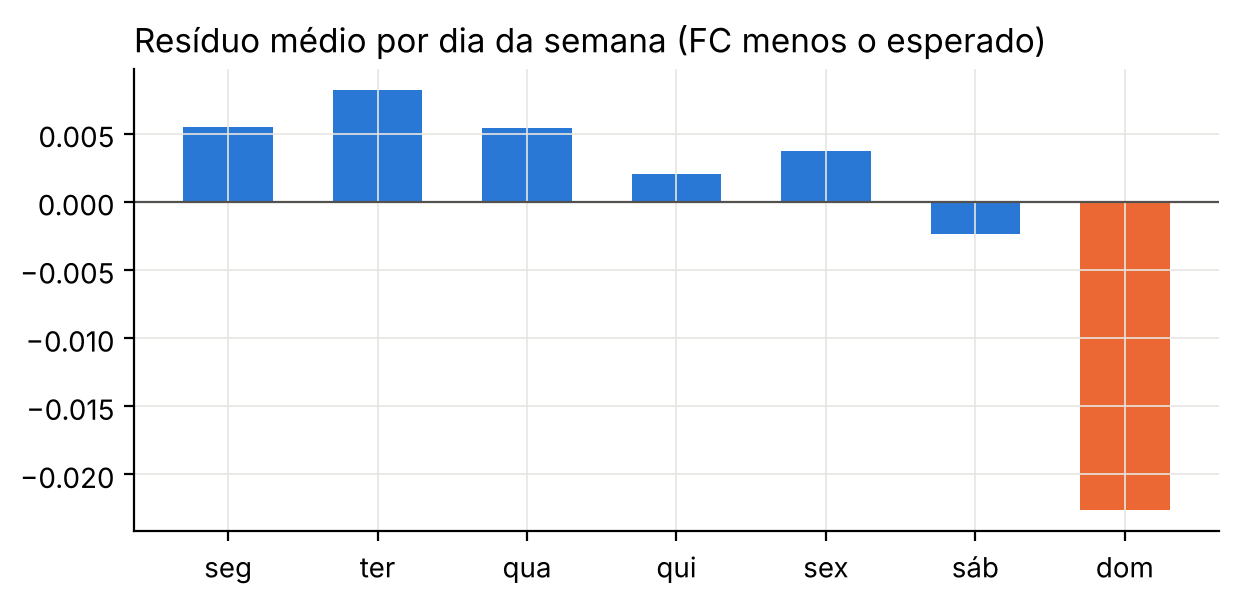

In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
cores = [LARANJA if d == 6 else AZUL for d in q5["dia_semana"]]
ax.bar(q5["dia"], q5["residuo_medio"], color=cores, width=0.6)
ax.axhline(0, color=CINZA, linewidth=0.8)
ax.set_title("Resíduo médio por dia da semana (FC menos o esperado)", loc="left")
plt.show()

**Interpretação:** o vento médio é igual em todos os dias da semana, como era de se esperar. Mas o FC de domingo é menor.

De segunda a sexta o resíduo fica perto de zero, no sábado cai um pouco e no domingo cai bem mais. Domingo é o dia de menor consumo de energia, e com consumo baixo sobra energia para cortar. A H3 (Parte B) testa se essa diferença é real ou acaso.

**Para a modelagem:** o efeito está no domingo (e um pouco no sábado). De segunda a sexta os dias se comportam igual, o que pesa contra treinar 7 modelos separados (ver Parte C).

## Consulta 6. Eventos excepcionais

**Pergunta:** quais dias ficaram muito longe do esperado, e por quê?

A consulta ordena os dias pelo resíduo (do pior para o melhor). A coluna `z_30d` usa uma função de janela para comparar cada dia com os 15 dias antes e depois: mostra quantos desvios-padrão o FC ficou longe da média desse período.

In [12]:
q6 = sql("""
with faixas as (
    select *, round(vento_100m_ms * 2) / 2 as faixa_vento from base
),
esperado as (
    select faixa_vento, avg(fc) as fc_esperado from faixas group by faixa_vento
),
residuos as (
    select f.data, f.fc, f.vento_100m_ms, f.dia_semana, f.nome_feriado, f.fc - e.fc_esperado as residuo
    from faixas f join esperado e using (faixa_vento)
)
select data, dayname(data) as dia, round(fc, 3) as fc, round(vento_100m_ms, 2) as vento,
       round(residuo, 3) as residuo,
       round((fc - avg(fc) over janela) / stddev(fc) over janela, 2) as z_30d,
       nome_feriado
from residuos
window janela as (order by data rows between 15 preceding and 15 following)
order by residuo
limit 12
""")
q6

,data,dia,fc,vento,residuo,z_30d,nome_feriado
0,2025-02-04,Tuesday,0.268,7.32,-0.205,-0.01,None
1,2025-02-03,Monday,0.262,6.83,-0.178,0.00,None
2,2025-02-12,Wednesday,0.280,6.76,-0.160,-0.64,None
3,2025-02-09,Sunday,0.284,6.83,-0.156,-0.30,None
4,2026-07-19,Sunday,0.377,8.96,-0.152,-0.33,None
5,2025-02-10,Monday,0.268,6.69,-0.139,-0.64,None
6,2025-02-07,Friday,0.270,6.29,-0.137,-0.36,None
7,2025-02-05,Wednesday,0.271,6.40,-0.136,-0.12,None
8,2025-02-11,Tuesday,0.273,6.73,-0.134,-0.64,None
9,2025-01-24,Friday,0.195,5.41,-0.130,-0.33,None


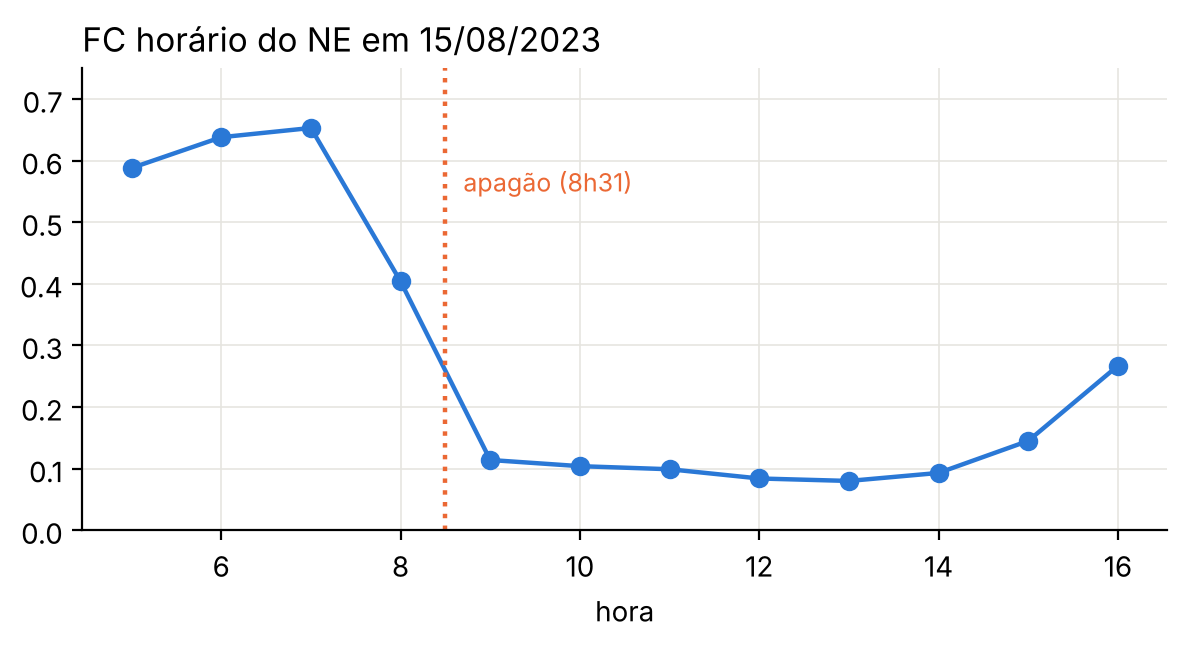

,data,fc,vento
0,2023-08-15,0.417,9.00
1,2025-09-28,0.408,9.02
2,2026-06-28,0.409,8.09


In [13]:
apagao = sql("""
select din_instante, round(fc, 3) as fc, round(vento_100m_ms, 2) as vento
from horario
where din_instante between '2023-08-15 05:00' and '2023-08-15 16:00'
order by din_instante
""")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(apagao["din_instante"].dt.hour, apagao["fc"], "o-", color=AZUL)
ax.axvline(8.5, color=LARANJA, linestyle=":"); ax.text(8.7, 0.55, "apagão (8h31)", color=LARANJA, fontsize=9)
ax.set_ylim(0, 0.75); ax.set_xlabel("hora"); ax.set_title("FC horário do NE em 15/08/2023", loc="left")
plt.show()
sql("select data, round(fc,3) fc, round(vento_100m_ms,2) vento from base where data in ('2023-08-15','2025-09-28','2026-06-28')")

**Interpretação dos eventos:**

| Evento | O que os dados mostram | Explicação provável |
| --- | --- | --- |
| Fevereiro de 2025 | 8 dos 12 piores dias, com vento de 6 a 7 m/s e FC perto de 0,27 | Mês com muitos cortes, com uma das principais linhas de transmissão fora de operação ([GESEL/UFRJ](https://gesel.ie.ufrj.br/wp-content/uploads/2025/05/Artigo-Robson-Rodrigues-e-Vinicius-Lucena_-Corte-de-energia-desafia-empresas-e-reacende-alerta-para-consumidor-27.05.2025.pdf)) |
| 28/09/2025 (domingo) | vento forte (9 m/s) e FC bem abaixo do esperado | Recorde de corte de geração renovável no NE ([apresentação no Senado](https://legis.senado.leg.br/sdleg-getter/documento/download/bc4c32eb-c40c-4e07-8596-34b2084ff09d)) |
| 28/06/2026 (domingo) | FC abaixo do esperado | O ONS cortou até 14,3 GW de eólica e solar no NE nesse domingo ([CNN Brasil](https://www.cnnbrasil.com.br/infra/ons-corta-uma-itaipu-de-eolica-e-solar-no-nordeste/)) |
| 15/08/2023 | o FC por hora cai de 0,65 para 0,11 entre 7h e 9h | Apagão nacional, que começou às 8h31. Na média do dia o evento fica escondido, mas aparece na série por hora |

Outros dias da lista, como 21/07/2024 e 19/07/2026, são domingos de vento forte. Não encontramos registro específico deles, mas seguem o mesmo padrão de corte em dia de consumo baixo.

**Para a modelagem:** esses eventos vêm de decisões da operação, não do clima, e nenhuma variável da base consegue prevê-los. Eles ficam na base (são reais), mas vão ser os maiores erros do modelo e devem ser comentados na avaliação.

## Consulta 7. Comparação Nordeste × Sul

**Pergunta:** o FC eólico do Sul se comporta como o do Nordeste?

O Sul é o único outro subsistema com usinas eólicas suficientes: 13 usinas ou conjuntos, cerca de 2 GW. O NE tem 190, com 18 a 32 GW. O Norte tem um único conjunto.

A primeira consulta calcula o FC diário das duas regiões **direto dos arquivos originais do ONS**, com a mesma limpeza da etapa 2. Não temos vento do Sul, então a comparação é só do FC.

In [14]:
arquivos_ons = (C.DIR_ONS / "*.parquet").as_posix()
con.sql(f"""
create or replace table fc_regiao_dia as
with ons as (
    select id_subsistema, nom_tipousina, din_instante,
           try_cast(nullif(trim(val_geracaoverificada), '') as double)   as ger,
           try_cast(nullif(trim(val_capacidadeinstalada), '') as double) as cap
    from read_parquet('{arquivos_ons}', union_by_name = true)
),
validos as (
    select * from ons
    where nom_tipousina = 'Eólica' and id_subsistema in ('NE', 'S')
      and ger is not null and cap > 0 and ger >= 0 and ger <= 1.10 * cap
)
select id_subsistema as subsistema, cast(din_instante as date) as data,
       sum(ger) / sum(cap) as fc, sum(cap) / count(distinct din_instante) as capacidade_mw
from validos
group by all
""")

# conferência: o FC do NE calculado aqui é igual ao da base da etapa 2?
sql("""select round(max(abs(r.fc - b.fc)), 6) as maior_diferenca
       from fc_regiao_dia r join base b on r.data = b.data and r.subsistema = 'NE'""")

,maior_diferenca
0,0.0


In [15]:
q7_mes = sql("""
pivot (select subsistema, month(data) as mes, avg(fc) as fc from fc_regiao_dia group by all)
on subsistema using round(first(fc), 3)
order by mes
""")
q7_resumo = sql("""
with com_ontem as (
    select *, lag(fc) over (partition by subsistema order by data) as fc_ontem
    from fc_regiao_dia
)
select subsistema,
       round(avg(fc), 3)                       as fc_medio,
       round(stddev(fc), 3)                    as desvio_diario,
       round(corr(fc, fc_ontem), 3)            as correlacao_com_ontem,
       round(avg(abs(fc - fc_ontem)), 3)       as erro_medio_repetindo_ontem,
       round(avg(capacidade_mw))               as capacidade_media_mw
from com_ontem
group by subsistema
""")
q7_domingo = sql("""
with por_ano as (
    select subsistema, year(data) as ano,
           avg(fc) filter (where dayofweek(data) = 0)           as fc_domingo,
           avg(fc) filter (where dayofweek(data) between 1 and 5) as fc_seg_sex
    from fc_regiao_dia
    group by all
)
pivot (select subsistema, ano, fc_domingo / fc_seg_sex - 1 as dif from por_ano)
on subsistema using round(first(dif), 3)
order by ano
""")
display(q7_resumo, q7_domingo)

,subsistema,fc_medio,desvio_diario,correlacao_com_ontem,erro_medio_repetindo_ontem,capacidade_media_mw
0,S,0.316,0.170,0.477,0.137,2090.0
1,NE,0.386,0.122,0.834,0.053,26559.0


,ano,NE,S
0,2022,0.007,0.073
1,2023,-0.063,-0.168
2,2024,-0.074,0.005
3,2025,-0.101,-0.198
4,2026,-0.151,-0.096


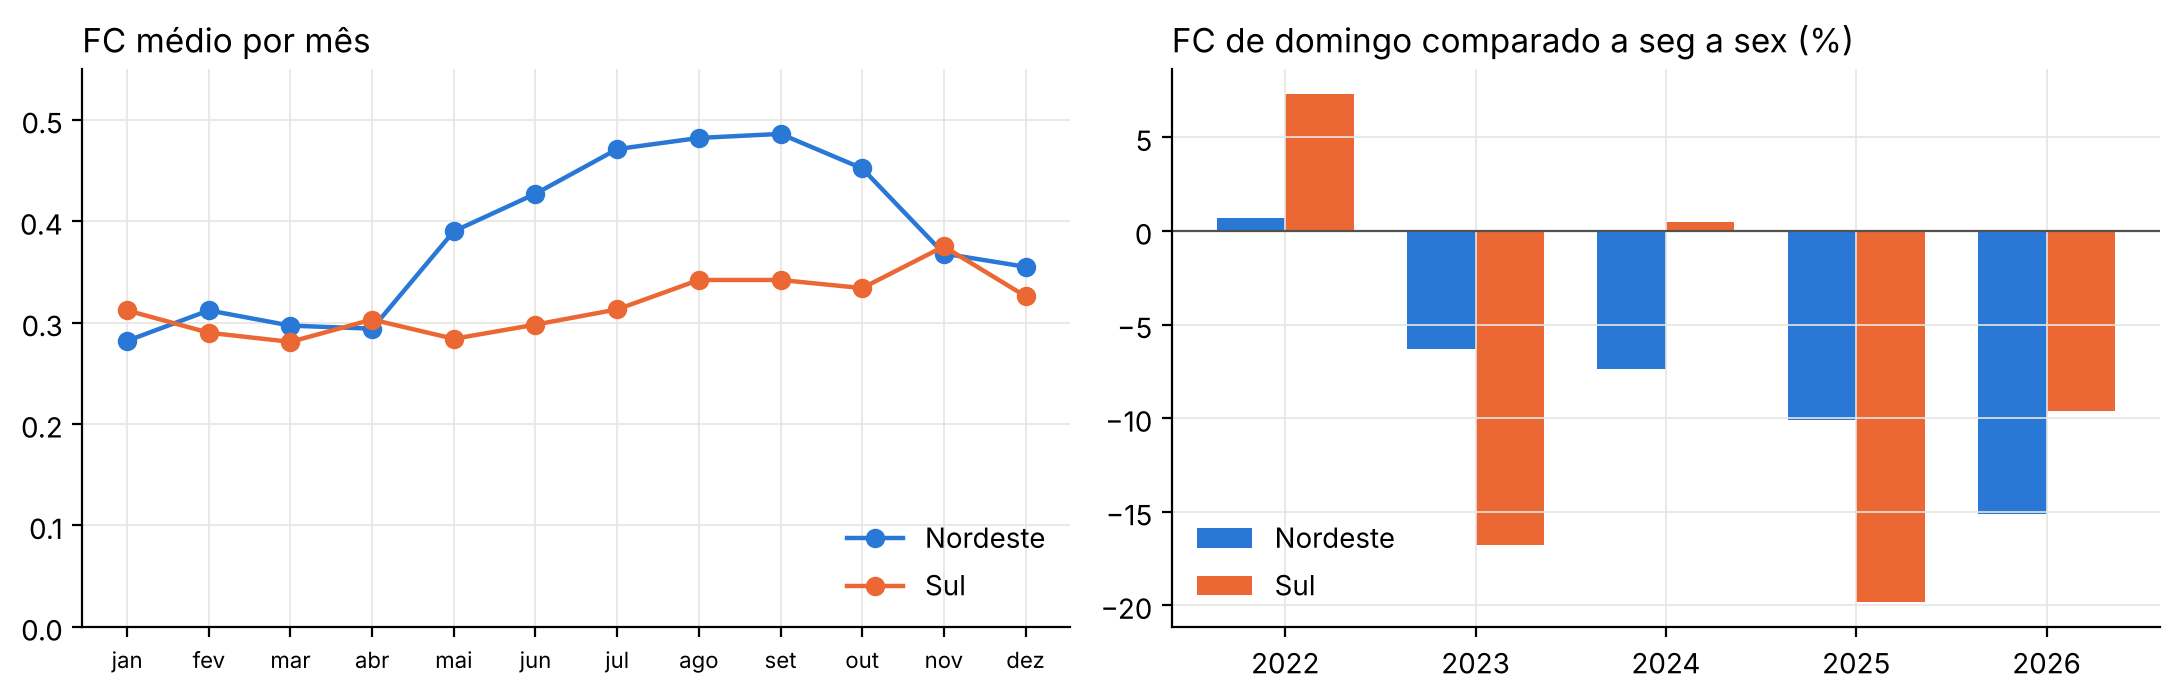

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
meses = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]
axs[0].plot(q7_mes["mes"], q7_mes["NE"], "o-", color=AZUL, label="Nordeste")
axs[0].plot(q7_mes["mes"], q7_mes["S"], "o-", color=LARANJA, label="Sul")
axs[0].set_xticks(range(1, 13)); axs[0].set_xticklabels(meses, fontsize=8); axs[0].set_ylim(0, 0.55)
axs[0].set_title("FC médio por mês", loc="left"); axs[0].legend(frameon=False, loc="lower right")
x = np.arange(len(q7_domingo))
axs[1].bar(x - 0.18, q7_domingo["NE"] * 100, width=0.36, color=AZUL, label="Nordeste")
axs[1].bar(x + 0.18, q7_domingo["S"] * 100, width=0.36, color=LARANJA, label="Sul")
axs[1].axhline(0, color=CINZA, linewidth=0.8)
axs[1].set_xticks(x); axs[1].set_xticklabels(q7_domingo["ano"])
axs[1].set_title("FC de domingo comparado a seg a sex (%)", loc="left"); axs[1].legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

**Interpretação:**

- **Estações:** o Sul quase não tem safra. O FC dele varia pouco no ano (0,28 a 0,38). O do NE vai de 0,28 a 0,49.
- **Previsibilidade:** no NE, o FC de hoje é muito parecido com o de ontem (correlação de 0,83). No Sul, bem menos (0,48). Repetir o valor de ontem erra em média 0,05 no NE e 0,14 no Sul. O vento do NE é mais regular; o do Sul depende da passagem de frentes frias.
- **Domingo:** no NE a queda de domingo aumenta a cada ano (de +1% em 2022 para -15% em 2026), junto com os cortes. No Sul o resultado muda de sinal de um ano para outro e parece ruído. Sem o vento do Sul não dá para separar vento de corte.

**Para a modelagem:** a diferença mais clara entre as regiões é a previsibilidade. Repetir o valor de ontem já funciona bem no NE, então é mais difícil superar isso lá do que no Sul. Para modelar o Sul, seria preciso rodar a etapa 2 com `SUBSISTEMA = "S"` para ter o vento da região.

# Parte B. Testes das hipóteses

**Um cuidado:** dias vizinhos são parecidos (correlação de 0,83 com o dia anterior). Se cada dia for tratado como independente, os testes parecem mais seguros do que são.

Por isso, em cada hipótese, o teste principal usa:

- **meses** em vez de dias, ou
- uma comparação **dentro da mesma semana**, ou
- **bootstrap em blocos**: sorteia trechos de 14 dias seguidos em vez de dias soltos, para manter a dependência entre dias vizinhos.

In [17]:
rng = np.random.default_rng(42)
b = sql("select * from base order by data")

def bootstrap_blocos(n, estatistica, B=2000, bloco=14):
    """Intervalo de 95% por bootstrap em blocos móveis (preserva a dependência entre dias vizinhos)."""
    valores = []
    for _ in range(B):
        inicios = rng.integers(0, n - bloco + 1, size=int(np.ceil(n / bloco)))
        idx = np.concatenate([np.arange(i, i + bloco) for i in inicios])[:n]
        valores.append(estatistica(idx))
    return np.percentile(valores, [2.5, 97.5])

## H1. O FC é maior na safra dos ventos (julho a outubro) do que no 1º semestre

**Teste principal:** compara as **médias mensais** (20 meses de safra contra 30 meses de janeiro a junho) com o teste t de Welch, e calcula o intervalo de confiança por bootstrap.

**Complemento:** teste de Mann-Whitney ano a ano, como foi previsto na definição do problema.

In [18]:
mensal = b.groupby(["ano", "mes"], as_index=False)["fc"].mean()
safra = mensal.loc[mensal["mes"].between(7, 10), "fc"].to_numpy()
semestre1 = mensal.loc[mensal["mes"] <= 6, "fc"].to_numpy()
dif = safra.mean() - semestre1.mean()
welch = stats.ttest_ind(safra, semestre1, equal_var=False)
boot = [rng.choice(safra, len(safra)).mean() - rng.choice(semestre1, len(semestre1)).mean() for _ in range(5000)]
ic = np.percentile(boot, [2.5, 97.5])
print(f"Diferença de FC (safra menos jan a jun): {dif:.3f}  IC 95% [{ic[0]:.3f}, {ic[1]:.3f}]")
print(f"Welch: t = {welch.statistic:.2f}, p = {welch.pvalue:.1e}")

por_ano = []
for ano, g in b.groupby("ano"):
    s, o = g.loc[g["safra_ventos"], "fc"], g.loc[g["mes"] <= 6, "fc"]
    por_ano.append({"ano": ano, "fc_safra": round(s.mean(), 3), "fc_jan_jun": round(o.mean(), 3),
                    "diferenca": round(s.mean() - o.mean(), 3),
                    "p_mann_whitney": stats.mannwhitneyu(s, o, alternative="two-sided").pvalue})
pd.DataFrame(por_ano)

Diferença de FC (safra menos jan a jun): 0.139  IC 95% [0.108, 0.171]
Welch: t = 8.52, p = 3.7e-11


,ano,fc_safra,fc_jan_jun,diferenca,p_mann_whitney
0,2022,0.536,0.341,0.195,1.927208e-35
1,2023,0.463,0.361,0.102,3.153930e-13
2,2024,0.484,0.307,0.176,3.381827e-32
3,2025,0.463,0.347,0.117,9.283219e-25
4,2026,0.417,0.311,0.106,3.591245e-21


**Conclusão H1: confirmada.** Na safra o FC é cerca de 0,14 maior (intervalo de confiança de 95%: 0,11 a 0,17), e isso acontece em todos os anos.

A diferença foi maior em 2022 e 2024 (0,18 a 0,20) e menor em 2023, 2025 e 2026 (0,10 a 0,12). Os cortes de geração, que crescem quando venta muito, reduzem o FC justamente na safra.

## H2. O vento a 100 m explica a maior parte da variação do FC

**Critério:** "maior parte" quer dizer R² acima de 0,5 (o vento explica mais da metade da variação).

**Teste:** regressão linear do FC pelo vento, com intervalo de confiança do R² por bootstrap em blocos. Também comparamos com o vento ao cubo e olhamos o R² de cada ano.

In [19]:
x, y = b["vento_100m_ms"].to_numpy(), b["fc"].to_numpy()
reg = stats.linregress(x, y)
ic_r2 = bootstrap_blocos(len(y), lambda i: stats.linregress(x[i], y[i]).rvalue ** 2)
print(f"FC = {reg.intercept:.3f} + {reg.slope:.4f} × vento   (cada 1 m/s a mais ≈ +{reg.slope:.3f} de FC)")
print(f"R² = {reg.rvalue**2:.3f}  IC 95% [{ic_r2[0]:.3f}, {ic_r2[1]:.3f}]")
print(f"R² usando o vento ao cubo: {stats.linregress(b['vento_100m_cubo'], y).rvalue**2:.3f}")
r2_ano = b.groupby("ano").apply(lambda g: stats.linregress(g["vento_100m_ms"], g["fc"]).rvalue ** 2, include_groups=False)
print("R² por ano:", r2_ano.round(3).to_dict())

FC = -0.102 + 0.0760 × vento   (cada 1 m/s a mais ≈ +0.076 de FC)
R² = 0.856  IC 95% [0.820, 0.884]
R² usando o vento ao cubo: 0.744
R² por ano: {2022: 0.954, 2023: 0.868, 2024: 0.931, 2025: 0.819, 2026: 0.893}


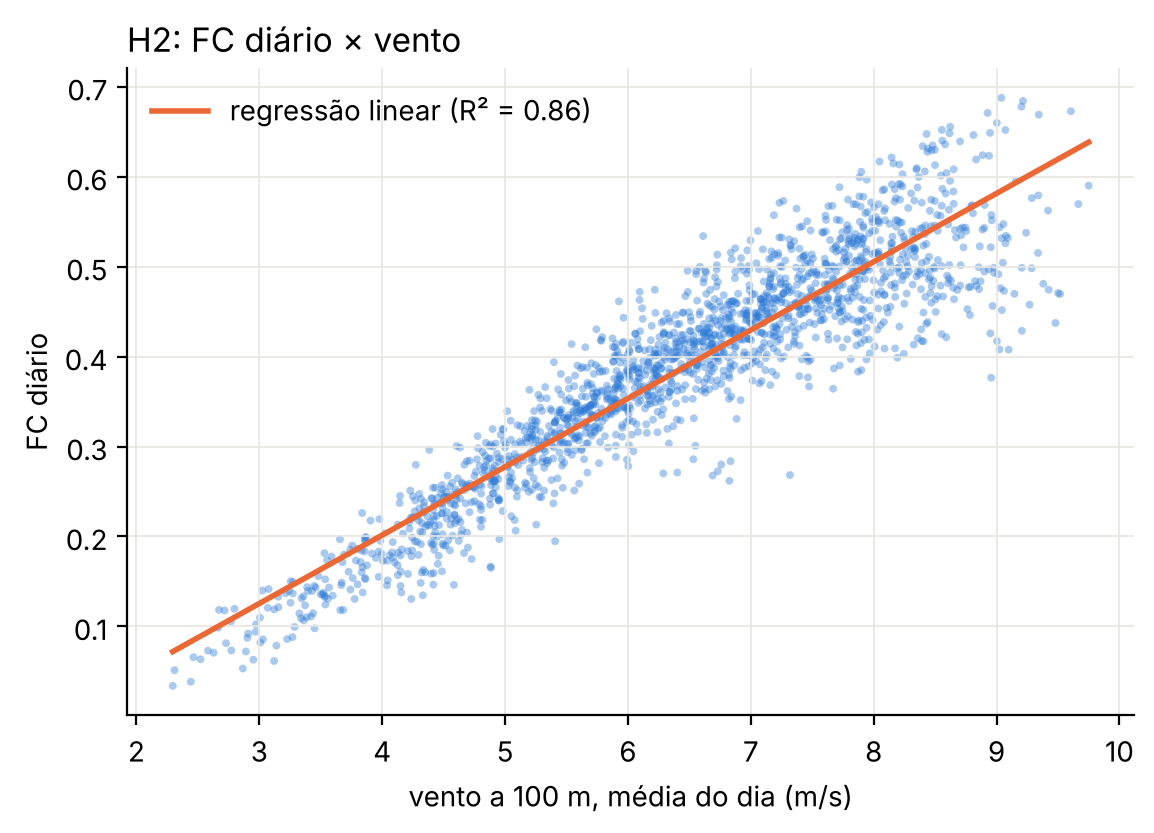

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(x, y, s=8, color=AZUL, alpha=0.4, edgecolor="none")
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, reg.intercept + reg.slope * xs, color=LARANJA, linewidth=2, label=f"regressão linear (R² = {reg.rvalue**2:.2f})")
ax.set_xlabel("vento a 100 m, média do dia (m/s)"); ax.set_ylabel("FC diário")
ax.set_title("H2: FC diário × vento", loc="left"); ax.legend(frameon=False, loc="upper left")
plt.show()

**Conclusão H2: confirmada.** Só o vento explica cerca de 86% da variação do FC diário (intervalo de 95%: 0,82 a 0,88), bem acima de 0,5. Cada 1 m/s a mais de vento no dia aumenta o FC em cerca de 0,076.

Dois detalhes para a modelagem:

- O vento ao cubo explica **menos** (R² de 0,74). A turbina tem um limite de potência, e os cortes também seguram o FC nos dias de muito vento. Por isso a curva real achata no alto.
- O R² muda de ano para ano: 0,95 em 2022 e 0,82 em 2025. O maior é o de 2022, antes do aumento dos cortes. Depois, parte da variação do FC passa a depender da operação, e não só do vento.

## H3. Em domingos e feriados o FC fica abaixo do esperado para o vento

**Teste principal (dentro da mesma semana):** para cada uma das 252 semanas, calculamos o resíduo do domingo menos o resíduo médio de segunda a sexta **da mesma semana**. Comparar dentro da semana tira o efeito da época do ano.

O resíduo vem de uma regressão do FC pelo vento e pelo ano (o ano entra para tirar a queda geral vista na consulta 3). Depois testamos se a média dessas diferenças é zero (teste t e teste de Wilcoxon).

**Feriados em dia útil:** testados à parte, comparando cada feriado com os dias úteis da mesma semana.

In [21]:
X = np.column_stack([np.ones(len(b)), b["vento_100m_ms"], pd.get_dummies(b["ano"], drop_first=True).astype(float)])
coef = np.linalg.lstsq(X, b["fc"].to_numpy(), rcond=None)[0]
b["residuo"] = b["fc"].to_numpy() - X @ coef
b["semana"] = b["data"].dt.to_period("W-SAT")            # semanas de domingo a sábado
util = (b["dia_semana"] < 5) & ~b["feriado_nacional"] & ~b["carnaval"]

semanas = pd.DataFrame({
    "domingo": b[b["dia_semana"] == 6].groupby("semana")["residuo"].mean(),
    "seg_sex": b[util].groupby("semana")["residuo"].mean(),
    "ano": b.groupby("semana")["ano"].first(),
}).dropna()
semanas["diferenca"] = semanas["domingo"] - semanas["seg_sex"]

d = semanas["diferenca"]
ic = stats.t.interval(0.95, len(d) - 1, d.mean(), stats.sem(d))
print(f"Semanas: {len(d)}  |  domingo menos seg a sex = {d.mean():.4f}  IC 95% [{ic[0]:.4f}, {ic[1]:.4f}]")
print(f"teste t: p = {stats.ttest_1samp(d, 0).pvalue:.1e}  |  Wilcoxon: p = {stats.wilcoxon(d).pvalue:.1e}")

h3_ano = semanas.groupby("ano")["diferenca"].agg(["mean", "sem", "count"])
h3_ano["ic_inf"] = h3_ano["mean"] - stats.t.ppf(0.975, h3_ano["count"] - 1) * h3_ano["sem"]
h3_ano["ic_sup"] = h3_ano["mean"] + stats.t.ppf(0.975, h3_ano["count"] - 1) * h3_ano["sem"]
h3_ano["p"] = semanas.groupby("ano")["diferenca"].apply(lambda s: stats.ttest_1samp(s, 0).pvalue)
h3_ano.round(4)

Semanas: 252  |  domingo menos seg a sex = -0.0277  IC 95% [-0.0331, -0.0222]
teste t: p = 7.2e-20  |  Wilcoxon: p = 3.7e-18


,mean,sem,count,ic_inf,ic_sup,p
ano,,,,,,
2022,0.0003,0.0044,52,-0.0086,0.0092,0.9454
2023,-0.0218,0.0047,53,-0.0312,-0.0124,0.0000
2024,-0.0381,0.0066,52,-0.0514,-0.0248,0.0000
2025,-0.0384,0.0064,52,-0.0513,-0.0255,0.0000
2026,-0.0431,0.0069,43,-0.0570,-0.0291,0.0000


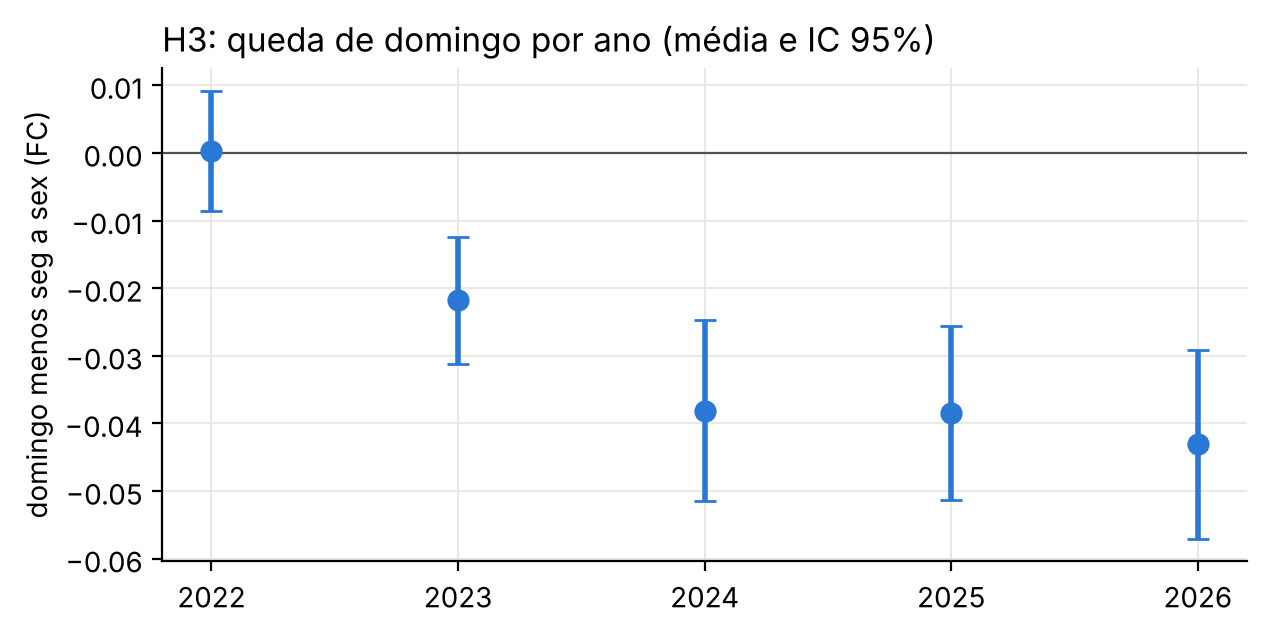

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.2))
anos = h3_ano.index.astype(int)
ax.errorbar(anos, h3_ano["mean"], yerr=[h3_ano["mean"] - h3_ano["ic_inf"], h3_ano["ic_sup"] - h3_ano["mean"]],
            fmt="o", color=AZUL, ecolor=AZUL, elinewidth=2, capsize=4, markersize=7)
ax.axhline(0, color=CINZA, linewidth=0.8)
ax.set_xticks(anos); ax.set_ylabel("domingo menos seg a sex (FC)")
ax.set_title("H3: queda de domingo por ano (média e IC 95%)", loc="left")
plt.show()

In [23]:
# Feriados que caem em dia útil vs. dias úteis da mesma semana
fer = b[(b["feriado_nacional"] | b["carnaval"]) & (b["dia_semana"] < 5)]
media_util_semana = b[util].groupby("semana")["residuo"].mean()
dif_fer = (fer.set_index("semana")["residuo"] - media_util_semana.reindex(fer["semana"]).to_numpy()).dropna()
print(f"Feriados/carnaval em dia útil: {len(dif_fer)}  |  diferença média = {dif_fer.mean():.4f}  "
      f"p = {stats.ttest_1samp(dif_fer, 0).pvalue:.2f}")

# A queda depende do vento? (corte só é necessário quando sobra geração)
b["vento_tercil"] = pd.qcut(b["vento_100m_ms"], 3, labels=["fraco", "médio", "forte"])
(b.assign(domingo=b["dia_semana"] == 6)
  .groupby(["vento_tercil", "domingo"], observed=True)["residuo"].mean().unstack().round(4))

Feriados/carnaval em dia útil: 42  |  diferença média = -0.0074  p = 0.16


domingo,False,True
vento_tercil,,
fraco,-0.0065,-0.0120
médio,0.0166,-0.0048
forte,0.0007,-0.0480


**Conclusão H3: confirmada para domingos, mas não para feriados.**

- **Domingos:** com o mesmo vento, o FC de domingo fica cerca de 0,028 abaixo dos dias úteis da mesma semana (intervalo de 95%: -0,033 a -0,022). Em 2022 a diferença era zero. A partir de 2023 ela aparece e cresce até cerca de -0,04, junto com o aumento dos cortes.
- **Depende do vento:** a queda de domingo é bem maior nos dias de vento forte. Com vento fraco quase não há corte, porque não sobra energia. Isso reforça a explicação pelo corte de geração.
- **Feriados em dia útil:** a diferença é pequena e pode ser acaso (só 42 casos). Talvez um feriado isolado reduza menos o consumo que um domingo, ou a amostra seja pequena demais. A hipótese falava de "domingos e feriados", mas os dados confirmam só a parte dos domingos.

# Parte C. O que isso muda na modelagem

| O que encontramos | Onde | O que fazer na modelagem |
| --- | --- | --- |
| O vento explica cerca de 86% do FC diário | H2 | O cenário (b), com o vento do dia, deve ser bem melhor que o cenário (a). A diferença entre os dois é um resultado importante |
| O FC de hoje é muito parecido com o de ontem | Consulta 7 | No cenário (a), o FC dos dias anteriores e médias móveis são as variáveis principais. Repetir o valor de ontem já é um baseline forte |
| Estações bem marcadas | Consulta 1, H1 | Usar o mês (ou o dia do ano) como variável |
| O mesmo vento gera menos FC a cada ano | Consultas 2, 3 e 4 | Incluir uma variável de tempo (ano) e dar mais peso aos dados recentes. O teste em 2026 vai mostrar se isso basta |
| Domingo tem FC menor, e o efeito cresce | Consulta 5, H3 | Variável de domingo ou dia não útil, de preferência combinada com o ano e com o vento |
| Segunda a sexta se comportam igual | Consulta 5 | 7 modelos por dia da semana treinariam com 1/7 dos dados para separar dias que não diferem. Vale comparar com um modelo para dia útil e outro para dia não útil, ou um modelo único com essas variáveis |
| Eventos da operação (fev/2025, apagão) | Consulta 6 | Ficam na base, mas vão gerar os maiores erros. Avaliar o modelo também sem esses dias |
| O Sul é bem menos previsível que o NE | Consulta 7 | Esperar resultados diferentes nas duas regiões. Para modelar o Sul é preciso o vento de lá |

**Limitações:** só temos dados de vento (temperatura e chuva pesam pouco para eólica). O vento vem de um modelo (reanálise), não de medição nas usinas. E não há dados diretos de corte de geração: a explicação por corte vem do padrão dos resíduos e das fontes citadas.